# Research attention concentrates on a subset of taxa

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

for candidate in (Path.cwd().resolve(), *Path.cwd().resolve().parents):
    if (candidate / "data_helpers").is_dir() and (candidate / "checklists").is_dir():
        PROJECT_ROOT = candidate
        break
else:
    raise FileNotFoundError("Could not locate the biodiversity repository root.")

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from data_helpers import results_config, visualization
from data_helpers.prep import taxa_analysis_prep
from data_helpers.analysis.taxa import skew as taxa_skew
from data_helpers.analysis.taxa import skew_plotting as taxa_skew_plotting
from data_helpers.analysis.taxa import geography as taxa_geography

In [2]:
visualization.apply_style()

RESULTS_CONFIG = results_config.load_results_config()
# One analysis key. Everything else read here is shared infrastructure: the two
# data-processing handoffs (taxa_analysis_prep, and the corpus for study countries).
CONFIG = RESULTS_CONFIG["taxonomic_lens"]
PREP_CONFIG = RESULTS_CONFIG["taxa_analysis_prep"]

MAPPING = taxa_analysis_prep.load_taxa_mapping(PROJECT_ROOT / PREP_CONFIG["taxa_group_mapping"])
BROAD_SCHEME = MAPPING["schemes"]["broad"]

BENCHMARK_GROUPS = tuple(CONFIG["benchmark_groups"])
BROAD_COLORS = {group: BROAD_SCHEME["group_colors"][group] for group in BENCHMARK_GROUPS}

PREPARED = taxa_analysis_prep.TaxaPreparedStore(PROJECT_ROOT / PREP_CONFIG["output_directory"])
RESULTS = taxa_skew.TaxaSkewResultStore(
    PROJECT_ROOT / CONFIG["output_directory"],
    table_subdirectory=CONFIG["table_subdirectory"],
    figure_subdirectory=CONFIG["figure_subdirectory"],
)
ARTIFACT_PREFIX = CONFIG["artifact_prefix"]


# Every exported file carries this result's prefix.
def artifact(name: str) -> str:
    return f"{ARTIFACT_PREFIX}_{name}"


print(f"Benchmark groups: {', '.join(BENCHMARK_GROUPS)}")
print(f"Stack order (bottom to top): {', '.join(CONFIG['benchmark_group_stack_order'])}")
print(f"Outputs: {CONFIG['output_directory']}")

Benchmark groups: Chordates, Non-chordate animals, Plants, Fungi, Other
Stack order (bottom to top): Non-chordate animals, Fungi, Other, Plants, Chordates
Outputs: notebooks/results/outputs/04_taxonomic_lens


## 1. One load, two denominators

The handoff is loaded once, over negative-direction evidence from complete years
2000-2025. **Universe** is every in-scope publication; **anchor** is the subset
resolving to at least one benchmarkable broad group — the scope every share below is
computed over. Both counts are reported in the `denominators` table below.

In [3]:
bundle = PREPARED.load(mapping=MAPPING)
print(f"Handoff: {len(bundle.articles):,} rows / {bundle.articles['UT'].nunique():,} unique UTs.")
print(f"Grouping rules SHA-256: {bundle.manifest['grouping_rules_sha256'][:16]}…")

anchor = taxa_skew.prepare_taxa_skew_from_prepared(
    bundle.articles,
    benchmark_groups=BENCHMARK_GROUPS,
    unresolved_group=CONFIG["unresolved_group"],
    match_status_audit=bundle.audit_frame("match_status"),
    group_reason_audit=bundle.audit_frame("broad_group_reason"),
    special_value_audit=bundle.audit_frame("special_value"),
    auxiliary_label_audit=bundle.audit_frame("auxiliary_labels"),
    direction=CONFIG["direction"],
    start_year=CONFIG["primary_start_year"],
    end_year=CONFIG["primary_end_year"],
)

# The universe is every in-scope publication; the anchor is those that resolve to a
# benchmarkable broad group.
UNIVERSE = bundle.articles[
    bundle.articles["s2_dir"].eq(CONFIG["direction"])
    & bundle.articles["publication_year"].between(
        CONFIG["primary_start_year"], CONFIG["primary_end_year"]
    )
]
N_UNIVERSE = int(UNIVERSE["UT"].nunique())
N_ANCHOR = int(anchor.included["UT"].nunique())

Handoff: 605,199 rows / 605,199 unique UTs.
Grouping rules SHA-256: 42222c9b8afd127c…


In [4]:
denominators = pd.DataFrame(
    [
        {
            "scope": "Universe (negative, 2000–2025)",
            "requirement": "in scope",
            "n_publications": N_UNIVERSE,
            "share_of_universe_pct": 100.0,
        },
        {
            "scope": "Anchor (the finding)",
            "requirement": "≥1 benchmarkable broad group",
            "n_publications": N_ANCHOR,
            "share_of_universe_pct": N_ANCHOR / N_UNIVERSE * 100,
        },
    ]
)
RESULTS.save_table(denominators, artifact("denominators"))
display(
    denominators.style.format(
        {"n_publications": "{:,}", "share_of_universe_pct": "{:.2f}%"}
    ).hide(axis="index")
)
print(
    f"{N_UNIVERSE - N_ANCHOR:,} in-scope publications name no benchmarkable group and are "
    "excluded from every number below."
)

Saved: notebooks/results/outputs/04_taxonomic_lens/csv/04_denominators.csv


scope,requirement,n_publications,share_of_universe_pct
"Universe (negative, 2000–2025)",in scope,"245,168",100.00%
Anchor (the finding),≥1 benchmarkable broad group,"171,791",70.07%


73,377 in-scope publications name no benchmarkable group and are excluded from every number below.


## 2. Attention versus described diversity

The comparison the finding rests on: each broad group's share of publication attention against
its share of described species. Attention is article-balanced — a publication naming two groups
contributes half a publication to each, never one to both.

In [5]:
benchmark = bundle.benchmark
anchor_analysis = taxa_skew.analyze_taxonomic_skew(
    anchor,
    benchmark,
    benchmark_groups=BENCHMARK_GROUPS,
    n_bootstrap=CONFIG["bootstrap_replicates"],
    seed=CONFIG["random_seed"],
)
RESULTS.save_table(anchor_analysis.comparison, artifact("attention_vs_described_diversity"))

display(
    anchor_analysis.comparison[
        [
            "broad_group",
            "n_unique_publications",
            "fractional_attention_share_pct",
            "attention_ci_low_pct",
            "attention_ci_high_pct",
            "described_species_count",
            "described_species_share_pct",
            "attention_minus_described_pp",
            "representation_ratio",
            "representation",
        ]
    ]
    .style.format(
        {
            "n_unique_publications": "{:,}",
            "fractional_attention_share_pct": "{:.2f}%",
            "attention_ci_low_pct": "{:.2f}%",
            "attention_ci_high_pct": "{:.2f}%",
            "described_species_count": "{:,}",
            "described_species_share_pct": "{:.2f}%",
            "attention_minus_described_pp": "{:+.2f} pp",
            "representation_ratio": "{:.2f}×",
        }
    )
    .hide(axis="index")
)

ANCHOR = anchor_analysis.comparison.set_index("broad_group")
for group in ("Chordates", "Non-chordate animals"):
    row = ANCHOR.loc[group]
    print(
        f"{group}: {row['fractional_attention_share_pct']:.1f}% of attention versus "
        f"{row['described_species_share_pct']:.1f}% of described species "
        f"({row['representation_ratio']:.2f}×, {row['attention_minus_described_pp']:+.1f} pp)."
    )

Saved: notebooks/results/outputs/04_taxonomic_lens/csv/04_attention_vs_described_diversity.csv


broad_group,n_unique_publications,fractional_attention_share_pct,attention_ci_low_pct,attention_ci_high_pct,described_species_count,described_species_share_pct,attention_minus_described_pp,representation_ratio,representation
Chordates,"64,161",34.83%,34.59%,35.05%,"120,268",4.61%,+30.21 pp,7.55×,Over-attended
Non-chordate animals,"39,952",19.71%,19.53%,19.90%,"1,694,587",65.00%,-45.29 pp,0.30×,Under-attended
Plants,"65,412",33.99%,33.77%,34.21%,"446,842",17.14%,+16.86 pp,1.98×,Over-attended
Fungi,"7,518",2.94%,2.87%,3.01%,"172,327",6.61%,-3.67 pp,0.44×,Under-attended
Other,"18,673",8.54%,8.41%,8.65%,"173,190",6.64%,+1.89 pp,1.28×,Over-attended


Chordates: 34.8% of attention versus 4.6% of described species (7.55×, +30.2 pp).
Non-chordate animals: 19.7% of attention versus 65.0% of described species (0.30×, -45.3 pp).


### 2a. Geographic comparison: chordate evidence versus threatened species

Each IPBES region's share of chordate evidence is compared with its share of IUCN threatened species (critically endangered, endangered and vulnerable) from Starnes et al. (2026), Data Table 1a ([doi:10.5281/zenodo.18348560](https://doi.org/10.5281/zenodo.18348560)), which reports counts by IPBES subregion.

- **Taxonomic scope.** The benchmark covers all comprehensively assessed taxa; the source has no breakdown by taxonomic group. The evidence side is the broad `Chordates` group (phylum Chordata).
- **Regional totals.** Subregion counts are summed to regions, giving regional occurrences of threatened species.
- **Evidence counting.** Each article counts once per region containing at least one of its study countries; articles spanning two regions count once in each.

In [6]:
from data_helpers.analysis.geo.geography import load_crosswalk
from data_helpers.analysis.taxa import threat_gap as taxa_threat_gap
from data_helpers.analysis.taxa import threat_gap_plotting as taxa_gap_plotting

GAP_GROUP = CONFIG["threat_gap_group"]
CROSSWALK = load_crosswalk()
publication_countries = taxa_geography.load_publication_countries(
    PROJECT_ROOT / CONFIG["geography_source"]
)


In [7]:
from data_helpers.analysis.taxa import threat_gap_starnes as taxa_threat_gap_starnes

STARNES_SOURCE = PROJECT_ROOT / CONFIG["threat_gap_starnes_source"]

# (1) Benchmark: Starnes CR+EN+VU, summed subregion -> region.
starnes_threat_regional = taxa_threat_gap_starnes.starnes_regional_threat_benchmark(
    STARNES_SOURCE, CROSSWALK, region_order=taxa_gap_plotting.REGION_ORDER,
)
RESULTS.save_table(starnes_threat_regional, artifact("starnes_threatened_species_by_region"))
print("(1) Starnes threat benchmark (all comprehensively-assessed taxa, CR+EN+VU):")
print(
    f"    {starnes_threat_regional.attrs['n_subregions_matched']} Starnes subregions "
    "matched to the repo's IPBES crosswalk (an unmatched subregion would have raised)."
)
display(
    starnes_threat_regional[["region", "threatened_species", "threat_share_pct"]]
    .style.format({"threatened_species": "{:,.0f}", "threat_share_pct": "{:.2f}%"})
    .hide(axis="index")
)
assert abs(starnes_threat_regional["threat_share_pct"].sum() - 100.0) < 1e-6

# (2) Evidence: Chordates, deduplicated to one occurrence per (article, region).
chordate_evidence_regional = taxa_threat_gap_starnes.pooled_regional_evidence(
    anchor.included, publication_countries, CROSSWALK,
    group=GAP_GROUP, region_order=taxa_gap_plotting.REGION_ORDER,
)
RESULTS.save_table(chordate_evidence_regional, artifact("chordate_evidence_by_region"))
print(
    f"\n(2) Evidence: {chordate_evidence_regional.attrs['n_articles_included']:,} "
    f"{GAP_GROUP.lower()} articles with a study country mapped to one of the four regions; "
    f"{chordate_evidence_regional.attrs['n_region_occurrences']:,} article-region "
    f"occurrences ({chordate_evidence_regional.attrs['n_multi_region_articles']:,} "
    "articles span more than one region and are counted once in each)."
)
display(
    chordate_evidence_regional
    .style.format({"n_publications": "{:,}", "evidence_share_pct": "{:.2f}%"})
    .hide(axis="index")
)
assert abs(chordate_evidence_regional["evidence_share_pct"].sum() - 100.0) < 1e-6

# (3) Combine. Both sides are region-level, so this is a label-preserving join.
gap_regions = taxa_threat_gap_starnes.combine_starnes_benchmark(
    chordate_evidence_regional, starnes_threat_regional
)
RESULTS.save_table(gap_regions, artifact("evidence_vs_starnes_threatened_by_region"))
print("\n(3) Combined regional comparison:")
display(
    gap_regions[
        [
            "region", "n_publications", "evidence_share_pct", "threatened_species",
            "threat_share_pct", "evidence_to_threat_ratio", "evidence_minus_threat_pp",
        ]
    ].style.format(
        {
            "n_publications": "{:,}",
            "evidence_share_pct": "{:.2f}%",
            "threatened_species": "{:,.0f}",
            "threat_share_pct": "{:.2f}%",
            "evidence_to_threat_ratio": "{:.2f}×",
            "evidence_minus_threat_pp": "{:+.2f} pp",
        }
    ).hide(axis="index")
)
for row in gap_regions.itertuples():
    print(
        f"    {row.region}: {row.evidence_share_pct:.1f}% of chordate evidence vs "
        f"{row.threat_share_pct:.1f}% of regional threatened-species occurrences "
        f"({row.evidence_to_threat_ratio:.2f}x)."
    )

# (4) Annual regional shares of chordate evidence; the pooled benchmark is the
# reference for the representation ratios.
gap_regional_trend = taxa_threat_gap.regional_evidence_trend(
    anchor.included, publication_countries, gap_regions, CROSSWALK, group=GAP_GROUP
)
gap_regional_summary = taxa_threat_gap.summarise_regional_trend(gap_regional_trend)
RESULTS.save_table(
    gap_regional_trend, artifact("chordate_evidence_regional_trend_starnes")
)
RESULTS.save_table(
    gap_regional_summary, artifact("chordate_evidence_regional_trend_summary_starnes")
)
display(
    gap_regional_summary.style.format(
        {
            "start_share_pct": "{:.2f}%",
            "end_share_pct": "{:.2f}%",
            "change_pp": "{:+.2f} pp",
            "slope_pp_per_decade": "{:+.2f}",
            "threat_share_pct": "{:.2f}%",
            "start_ratio": "{:.2f}×",
            "end_ratio": "{:.2f}×",
        }
    ).hide(axis="index")
)
for row in gap_regional_summary.itertuples():
    print(
        f"{row.region}: {row.start_share_pct:.1f}% -> {row.end_share_pct:.1f}% of "
        f"{GAP_GROUP.lower()} evidence ({row.slope_pp_per_decade:+.2f} pp/decade); "
        f"representation {row.start_ratio:.2f}x -> {row.end_ratio:.2f}x."
    )


Saved: notebooks/results/outputs/04_taxonomic_lens/csv/04_starnes_threatened_species_by_region.csv
(1) Starnes threat benchmark (all comprehensively-assessed taxa, CR+EN+VU):
    17 Starnes subregions matched to the repo's IPBES crosswalk (an unmatched subregion would have raised).


region,threatened_species,threat_share_pct
Africa,"3,780",19.83%
Asia and the Pacific,"7,784",40.83%
Americas,"6,440",33.78%
Europe and Central Asia,"1,061",5.57%


Saved: notebooks/results/outputs/04_taxonomic_lens/csv/04_chordate_evidence_by_region.csv

(2) Evidence: 38,333 chordates articles with a study country mapped to one of the four regions; 38,856 article-region occurrences (471 articles span more than one region and are counted once in each).


region,n_publications,evidence_share_pct
Africa,"3,327",8.56%
Asia and the Pacific,"10,571",27.21%
Americas,"16,454",42.35%
Europe and Central Asia,"8,504",21.89%


Saved: notebooks/results/outputs/04_taxonomic_lens/csv/04_evidence_vs_starnes_threatened_by_region.csv

(3) Combined regional comparison:


region,n_publications,evidence_share_pct,threatened_species,threat_share_pct,evidence_to_threat_ratio,evidence_minus_threat_pp
Europe and Central Asia,"8,504",21.89%,"1,061",5.57%,3.93×,+16.32 pp
Americas,"16,454",42.35%,"6,440",33.78%,1.25×,+8.57 pp
Asia and the Pacific,"10,571",27.21%,"7,784",40.83%,0.67×,-13.62 pp
Africa,"3,327",8.56%,"3,780",19.83%,0.43×,-11.26 pp


    Europe and Central Asia: 21.9% of chordate evidence vs 5.6% of regional threatened-species occurrences (3.93x).
    Americas: 42.3% of chordate evidence vs 33.8% of regional threatened-species occurrences (1.25x).
    Asia and the Pacific: 27.2% of chordate evidence vs 40.8% of regional threatened-species occurrences (0.67x).
    Africa: 8.6% of chordate evidence vs 19.8% of regional threatened-species occurrences (0.43x).


Saved: notebooks/results/outputs/04_taxonomic_lens/csv/04_chordate_evidence_regional_trend_starnes.csv
Saved: notebooks/results/outputs/04_taxonomic_lens/csv/04_chordate_evidence_regional_trend_summary_starnes.csv


region,start_year,end_year,start_share_pct,end_share_pct,change_pp,slope_pp_per_decade,threat_share_pct,start_ratio,end_ratio
Africa,2000,2025,6.90%,9.70%,+2.80 pp,+1.21,19.83%,0.35×,0.49×
Asia and the Pacific,2000,2025,17.24%,35.31%,+18.07 pp,+6.06,40.83%,0.42×,0.86×
Americas,2000,2025,50.38%,34.71%,-15.68 pp,-4.28,33.78%,1.49×,1.03×
Europe and Central Asia,2000,2025,25.48%,20.28%,-5.19 pp,-2.99,5.57%,4.58×,3.64×


Africa: 6.9% -> 9.7% of chordates evidence (+1.21 pp/decade); representation 0.35x -> 0.49x.
Asia and the Pacific: 17.2% -> 35.3% of chordates evidence (+6.06 pp/decade); representation 0.42x -> 0.86x.
Americas: 50.4% -> 34.7% of chordates evidence (-4.28 pp/decade); representation 1.49x -> 1.03x.
Europe and Central Asia: 25.5% -> 20.3% of chordates evidence (-2.99 pp/decade); representation 4.58x -> 3.64x.


### 2b. Composite figure

Supplementary Figure S6. Top row: taxonomic attention; bottom row: geographic attention to chordates.

- **Panel a** — described-species share and research-attention share of the five broad groups as two
  stacked bars on a shared 0–100% axis, joined by ribbons.
- **Panel b** — research-attention share of each broad group by publication year (`Other` is
  shown in panel a only).
- **Panel c** — each IPBES region's share of IUCN threatened-species occurrences (Starnes et
  al. 2026, summed across subregions; Section 2a) against its share of chordate evidence.
- **Panel d** — regional share of chordate evidence by publication year.

Per-group and per-region trend tables are exported alongside the figure.

Saved: notebooks/results/outputs/04_taxonomic_lens/csv/04_attention_trend_by_year.csv
Saved: notebooks/results/outputs/04_taxonomic_lens/csv/04_attention_trend_summary.csv


broad_group,start_share_pct,end_share_pct,change_pp,slope_pp_per_decade,start_representation_ratio,end_representation_ratio
Chordates,36.73%,32.35%,-4.38 pp,-1.63,7.96×,7.01×
Non-chordate animals,21.87%,19.08%,-2.78 pp,-1.06,0.34×,0.29×
Plants,32.10%,35.07%,+2.97 pp,+0.59,1.87×,2.05×
Fungi,2.55%,3.37%,+0.82 pp,+0.25,0.39×,0.51×
Other,6.75%,10.13%,+3.38 pp,+1.86,1.02×,1.52×



Annual output 1,940 (2000) -> 13,734 (2025): 7.1x.
Non-chordate animals: 21.9% -> 19.1% (-1.06 pp/decade); representation 0.34x -> 0.29x.
Chordates: 36.7% -> 32.3% (-1.63 pp/decade); representation 7.96x -> 7.01x.


Saved: notebooks/results/outputs/04_taxonomic_lens/figures/04_taxonomic_and_geographic_gap.pdf


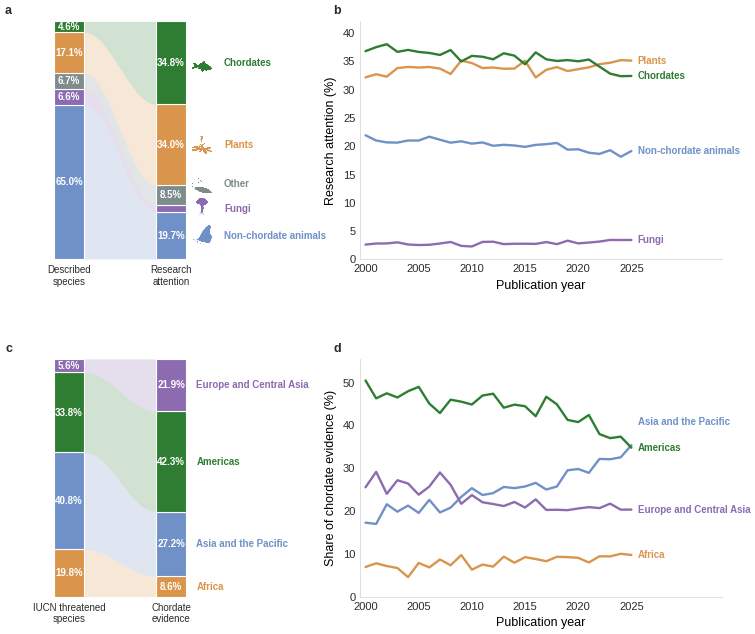

In [8]:
STACK_ORDER = tuple(CONFIG["benchmark_group_stack_order"])
RESIDUAL_GROUP = CONFIG["trend_residual_group"]

attention_trend = taxa_skew.taxonomic_attention_trend(
    anchor.included,
    benchmark_groups=BENCHMARK_GROUPS,
)
DESCRIBED_SHARES = ANCHOR["described_species_share_pct"].to_dict()
trend_summary = taxa_skew.summarise_attention_trend(
    attention_trend,
    described_shares=DESCRIBED_SHARES,
)
RESULTS.save_table(attention_trend, artifact("attention_trend_by_year"))
RESULTS.save_table(trend_summary, artifact("attention_trend_summary"))

display(
    trend_summary.set_index("broad_group")
    .reindex(BENCHMARK_GROUPS)
    .reset_index()[
        [
            "broad_group",
            "start_share_pct",
            "end_share_pct",
            "change_pp",
            "slope_pp_per_decade",
            "start_representation_ratio",
            "end_representation_ratio",
        ]
    ]
    .style.format(
        {
            "start_share_pct": "{:.2f}%",
            "end_share_pct": "{:.2f}%",
            "change_pp": "{:+.2f} pp",
            "slope_pp_per_decade": "{:+.2f}",
            "start_representation_ratio": "{:.2f}×",
            "end_representation_ratio": "{:.2f}×",
        }
    )
    .hide(axis="index")
)

YEARLY_TOTALS = (
    attention_trend.groupby("publication_year")["n_effective_publications_year"].first()
    if "n_effective_publications_year" in attention_trend
    else anchor.included.groupby("publication_year").size()
)
first_year, last_year = int(YEARLY_TOTALS.index.min()), int(YEARLY_TOTALS.index.max())
GROWTH_MULTIPLE = YEARLY_TOTALS.loc[last_year] / YEARLY_TOTALS.loc[first_year]
print(
    f"\nAnnual output {YEARLY_TOTALS.loc[first_year]:,.0f} ({first_year}) -> "
    f"{YEARLY_TOTALS.loc[last_year]:,.0f} ({last_year}): {GROWTH_MULTIPLE:.1f}x."
)
TREND = trend_summary.set_index("broad_group")
for group in ("Non-chordate animals", "Chordates"):
    row = TREND.loc[group]
    print(
        f"{group}: {row['start_share_pct']:.1f}% -> {row['end_share_pct']:.1f}% "
        f"({row['slope_pp_per_decade']:+.2f} pp/decade); representation "
        f"{row['start_representation_ratio']:.2f}x -> {row['end_representation_ratio']:.2f}x."
    )

# Combined 2x2: taxonomic comparison on top, geographic comparison below.
# `regional`/`regional_trend` are the Starnes-benchmarked tables from Section 2a;
# `region_left_caption` labels that all-taxa benchmark.
combined_figure = taxa_skew_plotting.plot_representation_and_trend(
    anchor_analysis.comparison,
    attention_trend,
    group_order=STACK_ORDER,
    group_colors=BROAD_COLORS,
    residual_group=RESIDUAL_GROUP,
    mapping=MAPPING,
    regional=gap_regions,
    regional_trend=gap_regional_trend,
    region_order=taxa_gap_plotting.REGION_ORDER,
    region_colors=taxa_gap_plotting.REGION_COLORS,
    region_left_caption="IUCN threatened\nspecies",
)
RESULTS.export_figure(
    combined_figure, artifact(CONFIG["combined_figure_filename"])
)
display(combined_figure)
plt.close(combined_figure)


In [9]:
RESULTS.save_json(
    {
        "analysis": "taxonomic attention versus described diversity, and its trajectory",
        "prepared_schema_version": bundle.manifest["schema_version"],
        "prepared_grouping_rules_sha256": bundle.manifest["grouping_rules_sha256"],
        "direction": CONFIG["direction"],
        "primary_years": [CONFIG["primary_start_year"], CONFIG["primary_end_year"]],
        "universe_publications": N_UNIVERSE,
        "anchor_publications": N_ANCHOR,
        "chordate_share_pct": round(
            float(ANCHOR.at["Chordates", "fractional_attention_share_pct"]), 4
        ),
        "non_chordate_animal_share_pct": round(
            float(ANCHOR.at["Non-chordate animals", "fractional_attention_share_pct"]), 4
        ),
        "annual_output_growth_multiple": round(float(GROWTH_MULTIPLE), 3),
        "geographic_benchmark_source": "Starnes et al. (2026), Zenodo doi:10.5281/zenodo.18348560",
        "geographic_benchmark_scope": "all IUCN comprehensively-assessed taxa (CR+EN+VU); "
        "evidence: the broad Chordates group (phylum Chordata)",
        "bootstrap_replicates": CONFIG["bootstrap_replicates"],
        "random_seed": CONFIG["random_seed"],
        "reported_tables": [artifact(name) for name in (
            "denominators.csv",
            "attention_vs_described_diversity.csv",
            "attention_trend_by_year.csv",
            "attention_trend_summary.csv",
        )] + [artifact(name) for name in (
            # Geographic comparison (Section 2a).
            "starnes_threatened_species_by_region.csv",
            "chordate_evidence_by_region.csv",
            "evidence_vs_starnes_threatened_by_region.csv",
            "chordate_evidence_regional_trend_starnes.csv",
            "chordate_evidence_regional_trend_summary_starnes.csv",
        )],

        "figures": [artifact(f"{CONFIG['combined_figure_filename']}.pdf")],
    },
    artifact("manifest"),
)
print("\nManifest written.")

Saved: notebooks/results/outputs/04_taxonomic_lens/csv/04_manifest.json

Manifest written.


## 3. The taxonomic hierarchy figure

`taxonomic_hierarchy.pdf` = Figure `taxonomic_hierarchy` in the main text — the sunburst
across Kingdom → Phylum → Class → Order, and the source of the Results paragraph's
Plantae/Chordata/Arthropoda/Mammalia/Insecta attention-vs-described-species figures.

### 3a. Pipeline contract and resolution audit

Reuses the accepted GBIF lineages from Section 1's resolution (exact and fuzzy-accepted
matches only). At each rank, duplicate paths within an article are collapsed and the
article rebalanced over its distinct complete paths — an Animalia-only item contributes at
kingdom only, an Arthropoda-only item at kingdom and phylum only, and so on. The GBIF side
streams the same fixed 28-Aug-2023 backbone as the Section 2 benchmark, restricted to
accepted species-rank rows, and separately reports how many rows have a complete path at
each rank.

**Taxonomy versions**: research taxa were resolved through GBIF's current v2 API, while
the described-species benchmark is the fixed 28-Aug-2023 public release (built by
`python -m data_helpers.sources.build_gbif_extract`; metadata in `data/gbif/extracted/eml.xml`). Kingdom containers for bacteria/archaea/viruses
bridge unambiguously; lower-rank renames are not guessed. Every comparison below keeps only
hierarchy paths common to both sources before renormalizing either side; the resolution and
alignment audits are exported alongside the figure.

In [10]:
from data_helpers.analysis.taxa import hierarchy as taxa_hierarchy
from data_helpers.analysis.taxa import hierarchy_plotting as taxa_hierarchy_plotting

HIERARCHY_CONFIG = CONFIG["hierarchy_exploration"]
taxa_matches = pd.read_parquet(PREPARED.match_path)
hierarchy_evidence = taxa_hierarchy.build_rank_hierarchy_evidence(
    taxa_matches,
    PROJECT_ROOT / HIERARCHY_CONFIG["gbif_source"],
    publication_ids=anchor.included["UT"],
    benchmark_groups=BENCHMARK_GROUPS,
)

rank_resolution = hierarchy_evidence.resolution_audit
rank_alignment = hierarchy_evidence.alignment_audit
gbif_rank_source_audit = hierarchy_evidence.gbif_source_audit.assign(
    source=HIERARCHY_CONFIG["gbif_source"],
    raw_archive_metadata=HIERARCHY_CONFIG["gbif_raw_archive_metadata"],
)
RESULTS.save_table(rank_resolution, artifact("rank_hierarchy_resolution_audit"))
RESULTS.save_table(rank_alignment, artifact("rank_hierarchy_alignment_audit"))
RESULTS.save_table(gbif_rank_source_audit, artifact("rank_hierarchy_gbif_source_audit"))

display(
    rank_resolution.style.format(
        {
            "research_resolved_publications": "{:,}",
            "research_share_of_anchor_pct": "{:.2f}%",
            "research_newly_unresolved_from_previous_rank": "{:,}",
            "gbif_resolved_species": "{:,}",
            "gbif_share_of_accepted_species_pct": "{:.2f}%",
            "gbif_newly_unresolved_from_previous_rank": "{:,}",
        }
    ).hide(axis="index")
)
display(
    rank_alignment.style.format(
        {
            "research_attention_on_common_paths_pct": "{:.2f}%",
            "gbif_species_on_common_paths_pct": "{:.2f}%",
            "research_publications_with_common_path": "{:,}",
        }
    ).hide(axis="index")
)
class_resolution = rank_resolution.set_index("rank").loc["class"]
class_alignment = rank_alignment.set_index("rank").loc["class"]
print(
    f"Class is present for {class_resolution['research_resolved_publications']:,.0f} anchor "
    f"publications ({class_resolution['research_share_of_anchor_pct']:.1f}%). Exact class paths "
    f"shared with the fixed GBIF snapshot retain "
    f"{class_alignment['research_publications_with_common_path']:,.0f} publications and "
    f"{class_alignment['research_attention_on_common_paths_pct']:.1f}% of the pre-alignment "
    "class-resolved attention."
)


Saved: notebooks/results/outputs/04_taxonomic_lens/csv/04_rank_hierarchy_resolution_audit.csv
Saved: notebooks/results/outputs/04_taxonomic_lens/csv/04_rank_hierarchy_alignment_audit.csv
Saved: notebooks/results/outputs/04_taxonomic_lens/csv/04_rank_hierarchy_gbif_source_audit.csv


rank,research_resolved_publications,research_share_of_anchor_pct,research_newly_unresolved_from_previous_rank,gbif_resolved_species,gbif_share_of_accepted_species_pct,gbif_newly_unresolved_from_previous_rank
kingdom,"171,791",100.00%,0,"2,614,593",100.00%,0
phylum,"161,668",94.11%,"10,123","2,601,849",99.51%,"12,744"
class,"158,500",92.26%,"3,168","2,498,498",95.56%,"103,351"
order,"149,709",87.15%,"8,791","2,418,924",92.52%,"79,574"


rank,n_research_paths,n_gbif_paths,n_exact_common_paths,research_attention_on_common_paths_pct,gbif_species_on_common_paths_pct,research_publications_with_common_path
kingdom,8,9,8,100.00%,99.96%,"171,791"
phylum,110,271,95,93.69%,98.50%,"154,348"
class,310,706,223,75.95%,96.92%,"124,816"
order,1026,2548,723,72.45%,90.91%,"113,342"


Class is present for 158,500 anchor publications (92.3%). Exact class paths shared with the fixed GBIF snapshot retain 124,816 publications and 75.9% of the pre-alignment class-resolved attention.


### 3b. Sunburst figure

Four rings (Kingdom → Phylum → Class → Order); angular span encodes research attention
only. The compact hierarchy under the wheel pairs each named group's (research attention,
described species) through Class — research attention on the Order-aligned 113,342-article
subset, described species on the full benchmarkable GBIF base (2,607,214 species, the same
denominator Section 2 uses). Complete Order detail is in the exported table.

Named-node selection: a Class expands to Order when at most 6 named Orders leave no more
than 5% residual (large Classes reaching 5% of global attention may use a relaxed
threshold); Orders reaching 1% on either aligned measure stay named. Everything below
threshold folds into a parent-coloured `Remaining` row; only the combined `Other kingdoms`
branch stays neutral grey.

Saved: notebooks/results/outputs/04_taxonomic_lens/csv/04_rank_hierarchy_order_comparison.csv
Saved: notebooks/results/outputs/04_taxonomic_lens/csv/04_rank_hierarchy_full_gbif_counts.csv
Saved: notebooks/results/outputs/04_taxonomic_lens/csv/04_rank_hierarchy_gbif_display_assignments.csv
Saved: notebooks/results/outputs/04_taxonomic_lens/csv/04_rank_hierarchy_sunburst_nodes.csv
Saved: notebooks/results/outputs/04_taxonomic_lens/csv/04_rank_hierarchy_sunburst_audit.csv


metric,value
Comparison research publications,113342.000000
Aligned GBIF species used for display selection,2199000.000000
Exact shared source Order paths,723.000000
Plotted hierarchy nodes,93.000000
Terminal plotted nodes,71.000000
Named Classes expanded to Order,11.000000
Large Classes using relaxed Order expansion,4.000000
Named Classes stopped at Class,18.000000
Named Kingdoms stopped at Kingdom,1.000000
Order maximum named children,6.000000


Saved: notebooks/results/outputs/04_taxonomic_lens/figures/04_taxonomic_hierarchy.pdf


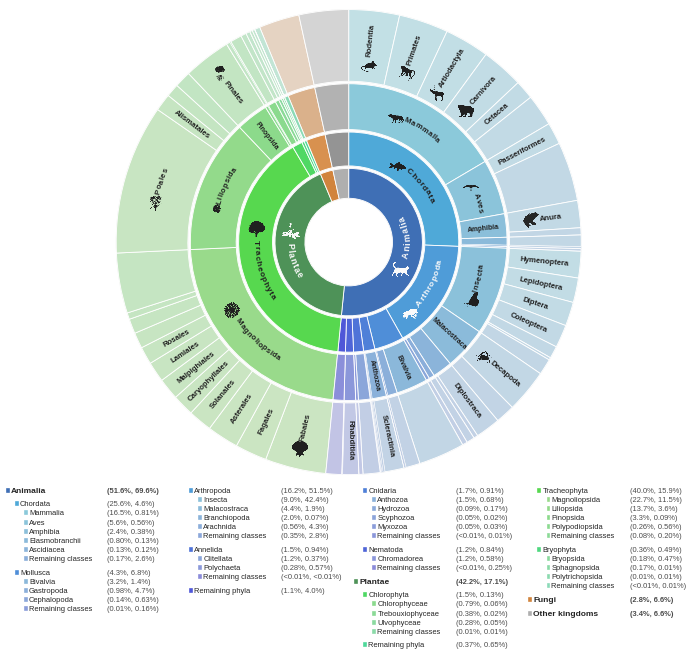

Saved: notebooks/results/outputs/04_taxonomic_lens/csv/04_rank_hierarchy_sunburst_manifest.json


In [11]:
SUNBURST_CONFIG = HIERARCHY_CONFIG["sunburst"]
order_comparison = taxa_hierarchy.compare_exact_rank_paths(
    hierarchy_evidence.research_attributions,
    hierarchy_evidence.gbif_counts,
    rank=SUNBURST_CONFIG["terminal_rank"],
)
sunburst_selection = taxa_hierarchy.build_research_attention_sunburst(
    order_comparison,
    major_kingdoms=SUNBURST_CONFIG["major_kingdoms"],
    terminal_kingdoms=SUNBURST_CONFIG["terminal_kingdoms"],
    phylum_min_within_parent_pct=SUNBURST_CONFIG["phylum_min_within_parent_pct"],
    class_min_within_parent_pct=SUNBURST_CONFIG["class_min_within_parent_pct"],
    order_max_children=SUNBURST_CONFIG["order_max_children"],
    order_max_other_within_parent_pct=SUNBURST_CONFIG["order_max_other_within_parent_pct"],
    relaxed_order_expansion_min_class_research_share_pct=SUNBURST_CONFIG["relaxed_order_expansion_min_class_research_share_pct"],
    order_named_min_global_share_pct=SUNBURST_CONFIG["order_named_min_global_share_pct"],
)
sunburst = taxa_hierarchy.apply_independent_gbif_benchmark(
    sunburst_selection,
    hierarchy_evidence.gbif_counts,
    bundle.benchmark.counts,
    root_group_mapping=SUNBURST_CONFIG["gbif_root_group_mapping"],
    phylum_min_within_parent_pct=SUNBURST_CONFIG["phylum_min_within_parent_pct"],
    class_min_within_parent_pct=SUNBURST_CONFIG["class_min_within_parent_pct"],
    order_named_min_global_share_pct=SUNBURST_CONFIG["order_named_min_global_share_pct"],
)
sunburst_nodes = sunburst.nodes.copy()
sunburst_nodes["plot_color"] = sunburst_nodes["node_id"].map(
    taxa_hierarchy_plotting.sunburst_node_colors(
        sunburst_nodes,
        rank_lightness=SUNBURST_CONFIG["rank_color_lightness"],
        rank_saturation=SUNBURST_CONFIG["rank_color_saturation"],
    )
)

# The public export carries the exact paths, paired measures, within-parent
# percentages, terminal flags, pruning reason, and colour used in the figure.
RESULTS.save_table(order_comparison, artifact("rank_hierarchy_order_comparison"))
RESULTS.save_table(hierarchy_evidence.gbif_counts, artifact("rank_hierarchy_full_gbif_counts"))
RESULTS.save_table(sunburst.assignments, artifact("rank_hierarchy_gbif_display_assignments"))
RESULTS.save_table(sunburst_nodes, artifact("rank_hierarchy_sunburst_nodes"))
RESULTS.save_table(sunburst.audit, artifact("rank_hierarchy_sunburst_audit"))
display(sunburst.audit.style.hide(axis="index"))

sunburst_figure = taxa_hierarchy_plotting.plot_research_attention_sunburst(
    sunburst_nodes,
    rank_lightness=SUNBURST_CONFIG["rank_color_lightness"],
    rank_saturation=SUNBURST_CONFIG["rank_color_saturation"],
    legend_order_min_global_share_pct=SUNBURST_CONFIG["legend_order_min_global_share_pct"],
    legend_show_orders=SUNBURST_CONFIG["legend_show_orders"],
    mapping=MAPPING,
    in_wheel_label_min_angle_deg=SUNBURST_CONFIG["in_wheel_label_min_angle_deg"],
    ring_widths=SUNBURST_CONFIG["rank_ring_widths"],
    class_label_min_angle_deg=SUNBURST_CONFIG["class_label_min_angle_deg"],
    order_label_min_angle_deg=SUNBURST_CONFIG["order_label_min_angle_deg"],
    extend_terminal_branches=SUNBURST_CONFIG["extend_terminal_branches"],
    inner_radius=SUNBURST_CONFIG["inner_radius"],
)
sunburst_labelled_taxa = list(sunburst_figure._sunburst_labelled_taxa)
sunburst_class_labelled_taxa = list(sunburst_figure._sunburst_class_labelled_taxa)
sunburst_order_labelled_taxa = list(sunburst_figure._sunburst_order_labelled_taxa)
sunburst_order_icon_taxa = list(sunburst_figure._sunburst_order_icon_taxa)
sunburst_terminal_continuations = list(sunburst_figure._sunburst_terminal_continuations)
RESULTS.export_figure(
    sunburst_figure, artifact(SUNBURST_CONFIG["figure_filename"])
)
display(sunburst_figure)
plt.close(sunburst_figure)

sunburst_manifest_path = RESULTS.save_json(
    {
        "analysis": "research-attention taxonomic sunburst (Figure taxonomic_hierarchy)",
        "rank_path": list(taxa_hierarchy.RANKS),
        "comparison_contract": "exact Order-aligned research geometry with an independent complete benchmarkable accepted-GBIF denominator",
        "angular_encoding": "article-balanced research attention",
        "described_species_encoding": "paired percentage through Class in the compact hierarchy, using the complete benchmarkable accepted-GBIF base; complete Order values remain in the exported table",
        "legend_terminal_rank": "order" if SUNBURST_CONFIG["legend_show_orders"] else "class",
        "remainder_contract": "display-only local complement: full parent GBIF count minus individually displayed full-GBIF child counts; actual assignments are exported",
        "order_remainder_encoding": "parent-coloured without hatching; combines every non-displayed Order and species lacking Order under the expanded Class",
        "in_wheel_labelled_taxa": sunburst_labelled_taxa,
        "in_wheel_class_labelled_taxa": sunburst_class_labelled_taxa,
        "in_wheel_order_labelled_taxa": sunburst_order_labelled_taxa,
        "in_wheel_order_icon_taxa": sunburst_order_icon_taxa,
        "terminal_continuations": sunburst_terminal_continuations,
        "in_wheel_clipart_mapping": {
            taxon: MAPPING["sunburst_clipart"][taxon]
            for taxon in sunburst_labelled_taxa
        },
        "in_wheel_order_clipart_mapping": {
            taxon: MAPPING["sunburst_order_clipart"][taxon]
            for taxon in sunburst_order_icon_taxa
        },
        "comparison_publications": int(order_comparison["comparison_research_publications"].iloc[0]),
        "comparison_gbif_species": int(sunburst_nodes["comparison_gbif_species"].iloc[0]),
        "aligned_gbif_species_used_for_display_selection": int(order_comparison["comparison_gbif_species"].iloc[0]),
        "n_exact_common_order_paths": len(order_comparison),
        "selection": SUNBURST_CONFIG,
        "tables": [
            artifact("rank_hierarchy_order_comparison.csv"),
            artifact("rank_hierarchy_full_gbif_counts.csv"),
            artifact("rank_hierarchy_gbif_display_assignments.csv"),
            artifact("rank_hierarchy_sunburst_nodes.csv"),
            artifact("rank_hierarchy_sunburst_audit.csv"),
        ],
        "figures": [
            artifact(f"{SUNBURST_CONFIG['figure_filename']}.pdf"),
        ],
    },
    artifact("rank_hierarchy_sunburst_manifest"),
)


In [12]:
# Taxa covered by the Order-aligned comparison behind the sunburst. Ranks to Order
# count distinct paths retained in the comparison; genus and species count distinct
# coded labels among the same publications (and, for reference, the whole anchor).
order_publication_ids = taxa_hierarchy.publications_on_common_paths(
    hierarchy_evidence.research_attributions,
    order_comparison,
    rank=SUNBURST_CONFIG["terminal_rank"],
)
assert len(order_publication_ids) == int(
    order_comparison["comparison_research_publications"].iloc[0]
)
taxon_count_frames = [
    taxa_hierarchy.distinct_path_taxa(
        order_comparison, rank=SUNBURST_CONFIG["terminal_rank"]
    ).assign(scope="Order-aligned paths", n_publications=len(order_publication_ids))
]
label_columns = {
    rank: f"taxa_{rank}_labels"
    for rank in ("genus", "species")
    if f"taxa_{rank}_labels" in bundle.articles.columns
}
if label_columns:
    for scope, ids in (
        ("Order-aligned publications", order_publication_ids),
        ("Anchor publications", anchor.included["UT"]),
    ):
        taxon_count_frames.append(
            taxa_hierarchy.distinct_publication_labels(
                bundle.articles, label_columns, publication_ids=ids
            ).assign(scope=scope)
        )
else:
    print("Genus/species label columns are not in the taxa handoff; species counts skipped.")
taxon_counts = pd.concat(taxon_count_frames, ignore_index=True)[
    ["scope", "rank", "n_taxa", "n_publications"]
]
RESULTS.save_table(taxon_counts, artifact("rank_hierarchy_taxon_counts"))
display(taxon_counts.style.format({"n_taxa": "{:,}", "n_publications": "{:,}"}).hide(axis="index"))


Saved: notebooks/results/outputs/04_taxonomic_lens/csv/04_rank_hierarchy_taxon_counts.csv


scope,rank,n_taxa,n_publications
Order-aligned paths,kingdom,8,"113,342"
Order-aligned paths,phylum,75,"113,342"
Order-aligned paths,class,203,"113,342"
Order-aligned paths,order,723,"113,342"
Order-aligned publications,genus,"14,215","113,342"
Order-aligned publications,species,"30,401","113,342"
Anchor publications,genus,"16,019","171,791"
Anchor publications,species,"35,143","171,791"
